# 01 — Twitter: какие данные мы исследуем

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from simulator import *
from agents import *
from experiments import *
assert Path('data/processed.npz').exists(), 'Сначала выполните data_pipeline.py'
data=load_data()
plt.rcParams.update({'figure.dpi':110,'axes.grid':True,'grid.alpha':.2})


Это анонимизированные запросы к распределённому кешу Twitter, не тексты твитов. Источник: [Twitter cache-trace](https://github.com/twitter/cache-trace), выборка cluster7 sample100 с [сервера CMU](https://ftp.pdl.cmu.edu/pub/datasets/twemcacheWorkload/open_source/sample100/). Авторы: Juncheng Yang, Yao Yue, Rashmi Vinayak, OSDI 2020. Лицензия CC BY 4.0.

Метод формирования sample100 не подтверждён: это самостоятельная выборочная нагрузка. Мы не умножаем показатели на 100 и не объявляем их показателями полного кластера. Исходник содержит немного больше недели; фиксируем первые 168 часов, остаток исключаем. Хеш файла и число исключённых строк сохранены в data/processed.json.

Колонки: timestamp (относительные секунды), анонимный ключ, key_size, value_size, client_id, operation, TTL. Размер 0 у чтения может означать промах, а не объект нулевого размера. Клиент не входит в ключ шардинга. Ключ преобразуется в UInt64 стабильным BLAKE2b, затем используется JCH, без float и Python hash().

In [2]:
meta=json.loads(Path('data/processed.json').read_text())
display(pd.Series(meta))
display(pd.Series(meta['operations'],name='requests').to_frame())
assert data['loads'].shape==(672,7,8)
assert np.all(data['loads'].sum(2)==data['loads'][:,0].sum(1)[:,None])
print('Контроль суммы запросов:',data['loads'][:,0].sum())

source                     https://ftp.pdl.cmu.edu/pub/datasets/twemcache...
sha256                     74c5922bb4d8c96a637006a1ee63dc40689cf94238ad90...
rows                                                                 9695769
unique_keys                                                            44744
first_second                                                               0
last_second                                                           625171
selected_last_second                                                  604799
source_rows                                                          9963780
excluded_tail_rows                                                    268011
slot_seconds                                                             900
hours                                                                    168
operations                                  {'get': 7814892, 'set': 1880877}
zero_value_rows                                                      1881656

,requests
get,7814892
set,1880877


Контроль суммы запросов: 9695769


Разбиение строго хронологическое: 96 часов train, 24 validation, 48 test. Шаг управления — 15 минут. Ниже показан только train; общая тестовая диаграмма появляется после фиксации моделей. Мощность серверов определяется по train, а не подбирается по победе агента.

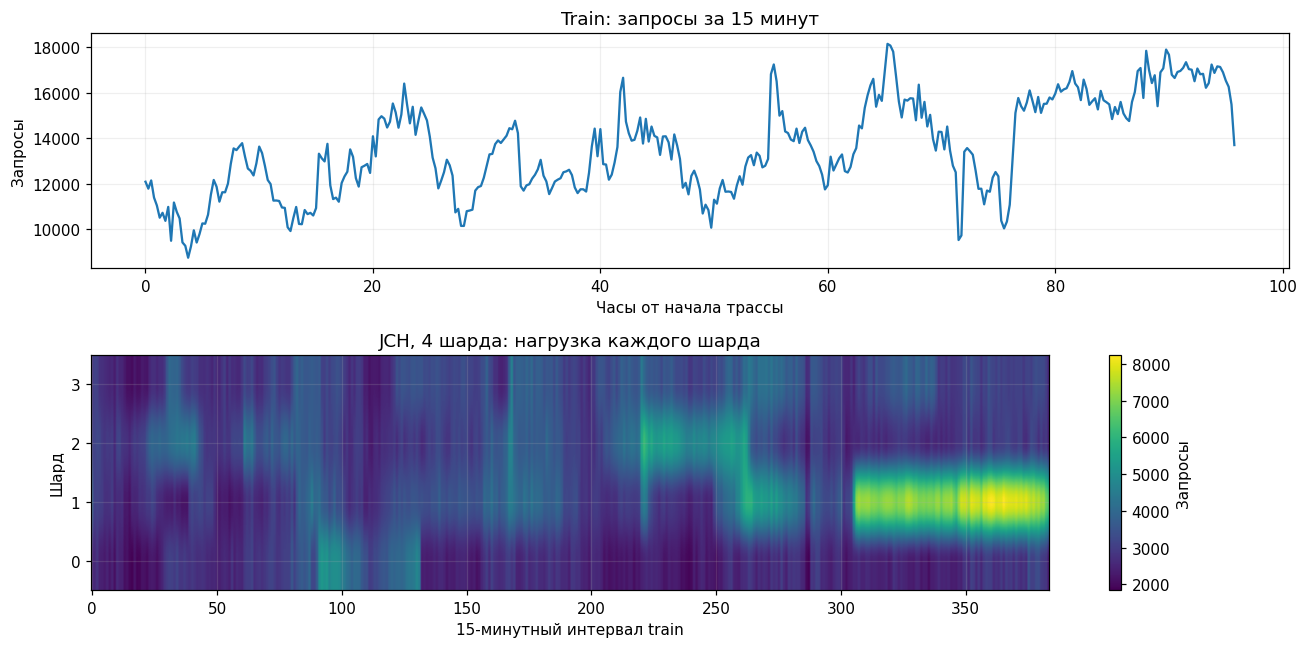

In [3]:
train_total=data['loads'][:384,0].sum(1)
fig,axes=plt.subplots(2,1,figsize=(12,6))
axes[0].plot(np.arange(384)/4,train_total)
axes[0].set(title='Train: запросы за 15 минут',xlabel='Часы от начала трассы',ylabel='Запросы')
image=axes[1].imshow(data['loads'][:384,2,:4].T,aspect='auto',origin='lower')
axes[1].set(title='JCH, 4 шарда: нагрузка каждого шарда',xlabel='15-минутный интервал train',ylabel='Шард')
fig.colorbar(image,ax=axes[1],label='Запросы')
fig.tight_layout();fig.savefig('results/data_train.png');plt.show()

Для иллюстрации механики JCH ниже — отдельный детерминированный набор ключей, не результаты Twitter. Он показывает минимальное перемещение при добавлении одного шарда. Это не доказательство равномерной нагрузки реальных ключей.

In [4]:
from data_pipeline import jch
keys=range(10000)
for old,new in [(2,3),(4,5),(7,8)]:
    changed=sum(jch(k,old)!=jch(k,new) for k in keys)
    modulo=sum(k%old!=k%new for k in keys)
    print(f'{old} → {new}: JCH {changed/100:.2f}%, modulo {modulo/100:.2f}% ключей')

2 → 3: JCH 33.42%, modulo 66.66% ключей
4 → 5: JCH 19.96%, modulo 80.00% ключей
7 → 8: JCH 12.90%, modulo 87.47% ключей
